# Жилые дома Красноярска
### Исследование базы и доступности инфраструктуры

**Часть 1.** Распределения, корреляции, качество данных и наблюдения.  
**Часть 2.** Дашборд для сравнения районов и поиска дома рядом с нужными объектами.

Источник — лист «Данные» приложенной книги, сформированной 18.11.2026 по OpenStreetMap. По листу «Методика», покрытие города и разметка инфраструктуры неполные. Расстояния измерены по прямой до объектов в выгрузке. Класс жилья и значительная часть значений материала стен рассчитаны эвристически, загрязнение воздуха смоделировано.

**Запуск.** Держите файл `krasnoyarsk_helpers.py` рядом с ноутбуком. Исходный XLSX должен лежать в папке проекта рядом с ноутбуком. Для пересчёта выполните все ячейки. Библиотеки Python для запуска — pandas, openpyxl, matplotlib и plotly. Графики анализа сделаны в Matplotlib. В конце есть интерактивный дашборд Plotly и текстовая сводка по районам. Для показа слайдов в браузере выполните в папке ноутбука команду ниже при установленном nbconvert.

    jupyter nbconvert Krasnoyarsk_Visualisation.ipynb --to slides --no-input --post serve

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

import krasnoyarsk_helpers


from krasnoyarsk_helpers import (
    address, amber, blue, box, category, coordinates, district_bar, floors,
    grid, histogram, ink, panels, stop, style, teal,
)

path = Path(krasnoyarsk_helpers.__file__).with_name('Krasnoyarsk_baza_zhilykh_domov_1.xlsx')

raw = pd.read_excel(path, sheet_name='Данные', keep_default_na=False)
data = raw.replace(r'^\s*(?:информация отсутствует)?\s*$', np.nan, regex=True)
district = 'Район'
school = 'Школа, м'
kindergarten = 'Детский сад, м'
park = 'Парк, м'
air = 'Загрязнение воздуха, % (модель)'
court = 'Закрытый двор'
parking = 'Парковка'
playground = 'Детская площадка'
# В исходной базе нет данных об ограждениях.
data[court] = np.nan
data[floors] = pd.to_numeric(data[floors], errors='coerce')

# Разбираем координаты домов.
geo = data[coordinates].str.split(',', n=1, expand=True).apply(pd.to_numeric, errors='coerce')
geo.columns = ['Широта', 'Долгота']
valid_geo = geo['Широта'].between(-90, 90) & geo['Долгота'].between(-180, 180)
geo = geo.loc[valid_geo]

distances = [col for col in raw if col.endswith(', м')]
numeric = distances + [floors, air]
service = ['№', address, coordinates]
categorical = [col for col in raw if col not in numeric + service]
names = {stop: 'Остановка, м', 'Набережная Енисея, м': 'До воды, м',
         air: 'Загрязнение (модель), %', 'Застройщик — оценка': 'Оценка застройщика',
         'УК — оценка': 'Оценка УК', '№': '№ записи'}
short = {col: names.get(col, col) for col in raw}
plt.rcParams.update({
    'figure.dpi': 115, 'font.family': 'DejaVu Sans', 'font.size': 11,
    'text.color': ink, 'axes.labelcolor': ink, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.edgecolor': grid, 'axes.titleweight': 'bold',
    'xtick.color': ink, 'ytick.color': ink, 'axes.axisbelow': True,
})
pio.renderers.default = 'plotly_mimetype+notebook'

In [51]:
data.describe()

,№,Этажность,"Ближайшая остановка, м","Загрязнение воздуха, % (модель)","Парк, м",Закрытый двор,"Школа, м","ТЦ, м","Детский сад, м","Аптека, м","Больница, м","Развлечения, м","Набережная Енисея, м","СТО, м","Травмпункт, м"
count,9132.000000,7409.000000,9132.000000,9132.000000,9132.000000,0.0,9132.000000,9132.000000,9132.000000,9132.000000,9132.000000,9132.000000,9132.000000,9132.000000,9132.000000
mean,4566.500000,3.123498,2597.042159,9.426522,1323.850197,NaN,1431.657140,2014.689991,1361.062308,1481.059680,1438.448642,1449.658563,3229.050482,2243.879654,3653.123303
std,2636.325663,4.097226,2798.461342,0.514152,1819.073400,NaN,1879.093878,1645.986382,1772.430413,1824.644358,1802.362646,1741.035639,1768.019013,2380.088950,2208.009068
min,1.000000,1.000000,8.000000,8.500000,7.000000,NaN,0.000000,0.000000,3.000000,1.000000,0.000000,0.000000,52.000000,0.000000,37.000000
25%,2283.750000,1.000000,684.750000,8.900000,234.000000,NaN,340.000000,875.000000,309.000000,357.000000,361.750000,340.750000,1853.750000,669.000000,2233.000000
50%,4566.500000,1.000000,1475.000000,9.400000,475.000000,NaN,573.000000,1474.000000,610.000000,643.500000,697.000000,700.000000,3015.000000,1182.000000,3050.000000
75%,6849.250000,4.000000,4212.500000,10.000000,1502.000000,NaN,1622.750000,2494.250000,1301.000000,1886.000000,1608.500000,1749.750000,4003.000000,3218.000000,4503.500000
max,9132.000000,26.000000,11997.000000,10.000000,8218.000000,NaN,8310.000000,8508.000000,8124.000000,8392.000000,8886.000000,8426.000000,8813.000000,10682.000000,10959.000000


## 1.1 · Числовые поля

К числовым полям относятся расстояния до объектов, этажность и модельный показатель загрязнения воздуха. Сначала посмотрим на расстояния.

По горизонтали — расстояние в метрах, по вертикали — сколько записей попало в интервал. У каждого объекта своя шкала.

Для остановок шаг составляет 500 м. Первый столбик объединяет расстояния от 0 до 499 м. Фактический минимум указан рядом со столбиком.

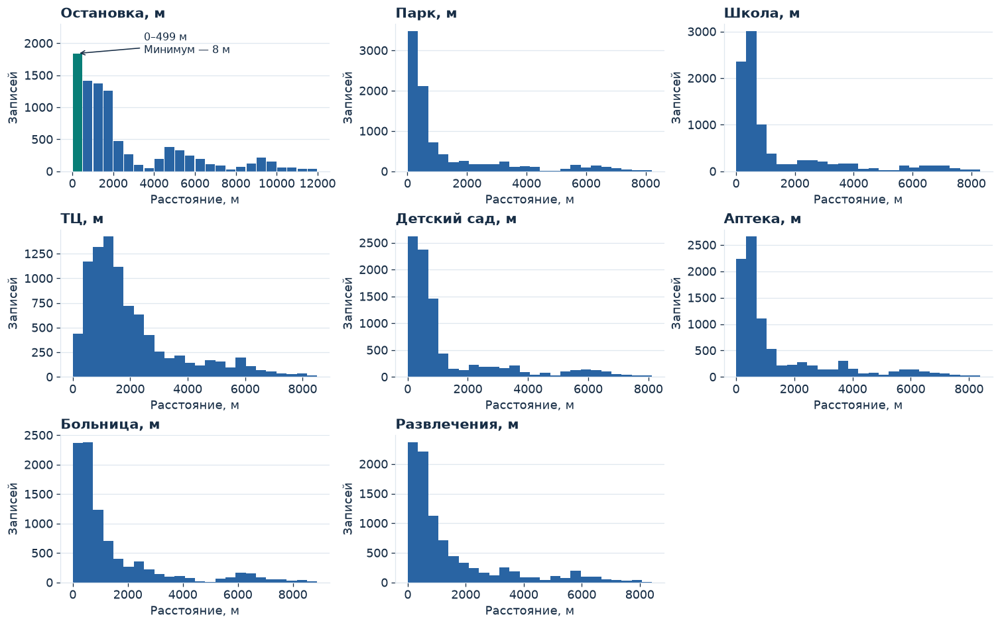

In [2]:
panels(distances[:8], histogram, short, ncols=3, height=2.7, data=data)

## 1.2 · Остальные расстояния, этажность и воздух

В гистограмму этажности входят строки с указанным числом этажей. Пик у 10% относится к модельной шкале загрязнения из источника.

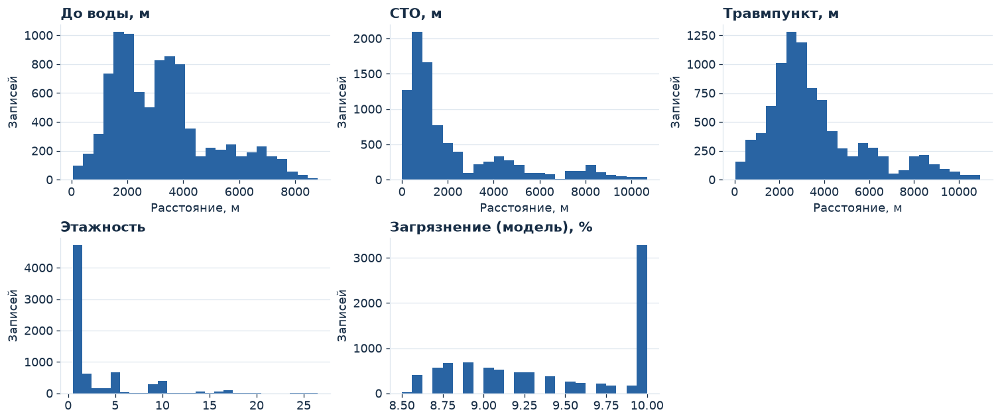

Этажность указана у 7,409 из 9,132 записей. Одноэтажные дома составляют 63.6% среди записей с известной этажностью.


In [3]:
panels(numeric[8:], histogram, short, ncols=3, height=2.7, data=data)
print(
    f'Этажность указана у {data[floors].count():,} из {len(raw):,} записей. '
    f'Одноэтажные дома составляют {data[floors].eq(1).sum() / data[floors].count():.1%} '
    'среди записей с известной этажностью.'
)

## 1.3 · Категориальные поля

Район, материал стен, класс жилья, поля застройщика и УК, парковка, закрытый двор и детская площадка.

Для категорий с большим числом значений показываем четыре самых частых. Остальные объединяем в «прочие». Пропуски тоже учитываем.

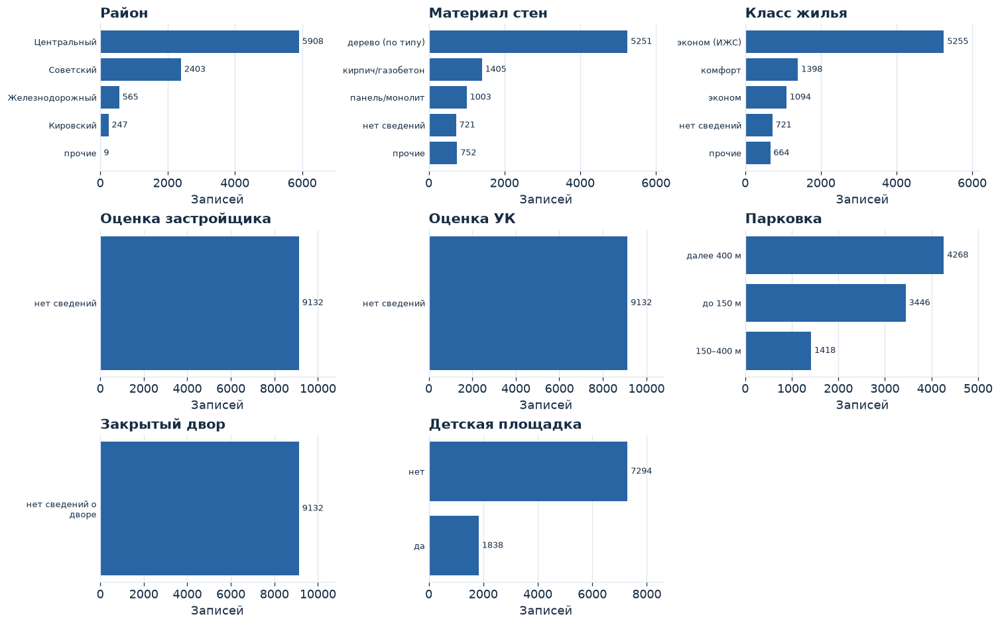

In [4]:
panels(categorical, category, short, ncols=3, height=2.7, geo=geo, raw=raw, data=data)

### Служебные поля

Номер записи нужен для идентификации, адрес — для поиска, координаты — для карты. В матрицу корреляций эти поля не входят.

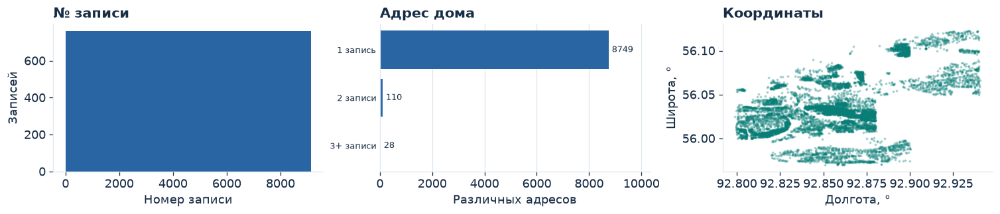

In [5]:
panels(service, category, short, ncols=3, height=2.7, geo=geo, raw=raw, data=data)

## 1.4 · Матрица корреляций

Число в клетке — корреляция Спирмена для пары признаков. Ближе к +1 — обычно растут вместе, ближе к −1 — один растёт, другой падает. Модель воздуха уже учитывает расстояние до парка.

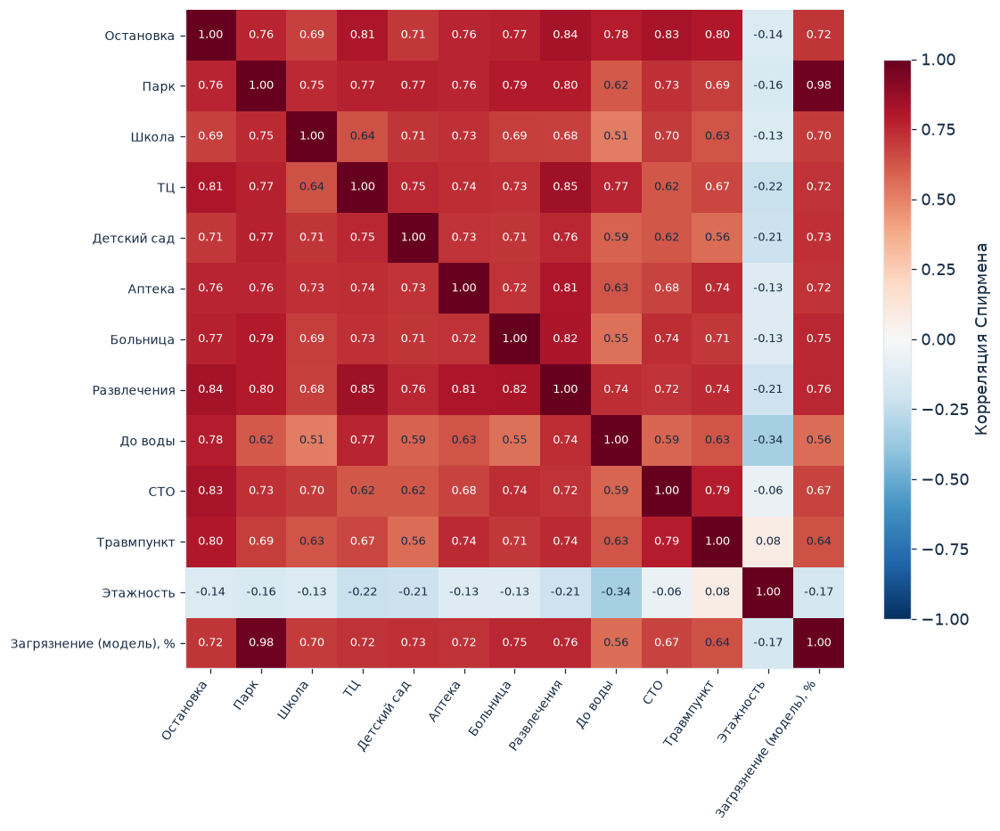

In [6]:
rho = data[numeric].corr(method='spearman')
labels = [short[col].removesuffix(', м') for col in numeric]

fig, ax = plt.subplots(figsize=(10, 8), layout='constrained')
matrix = ax.imshow(rho, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=55, ha='right', fontsize=9)
ax.set_yticks(range(len(labels)), labels, fontsize=9)
for row, values in enumerate(rho.to_numpy()):
    for col, value in enumerate(values):
        color = 'white' if abs(value) > .65 else ink
        ax.text(col, row, f'{value:.2f}', ha='center', va='center', fontsize=8, color=color)
fig.colorbar(matrix, ax=ax, label='Корреляция Спирмена', shrink=.85)
plt.show()

## 1.5 · Две самые сильные связи между расстояниями

Каждая точка — одна запись о доме. Если облако точек тянется вверх и вправо, оба расстояния чаще увеличиваются вместе.

ТЦ, м / Развлечения, м — 0.85
Остановка, м / Развлечения, м — 0.84


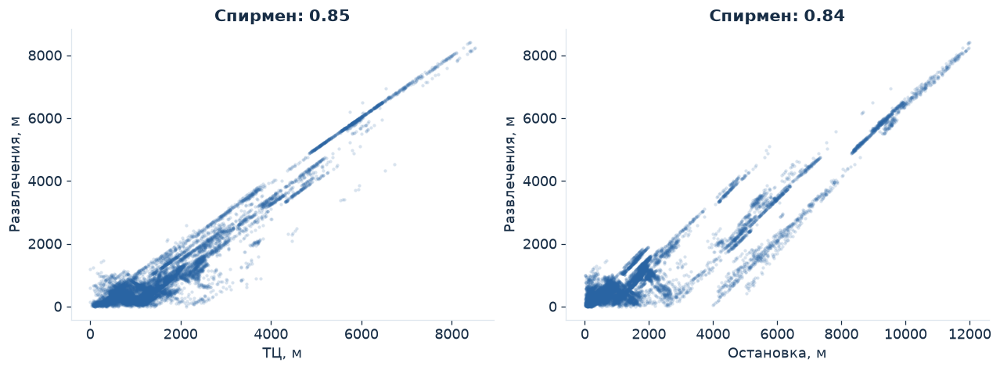

In [7]:
corr_distance = rho.loc[distances, distances]
# Берём верхнюю половину матрицы, чтобы не считать пары дважды.
upper = np.triu(np.ones(corr_distance.shape, dtype=bool), k=1)
pairs = corr_distance.where(upper).stack()
top_pairs = pairs.reindex(pairs.abs().nlargest(2).index)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for ax, ((left, right), coeff) in zip(axes, top_pairs.items()):
    ax.scatter(data[left], data[right], s=7, alpha=.18, color=blue, linewidths=0)
    ax.set(xlabel=short[left], ylabel=short[right], title=f'Спирмен: {coeff:.2f}')
    print(f'{short[left]} / {short[right]} — {coeff:.2f}')
plt.show()

## 1.6 · Разброс расстояний

Вертикальная линия внутри ящика — медиана. В ящике лежат средние 50% значений. Точки за усами — значения, которые стоит посмотреть отдельно.

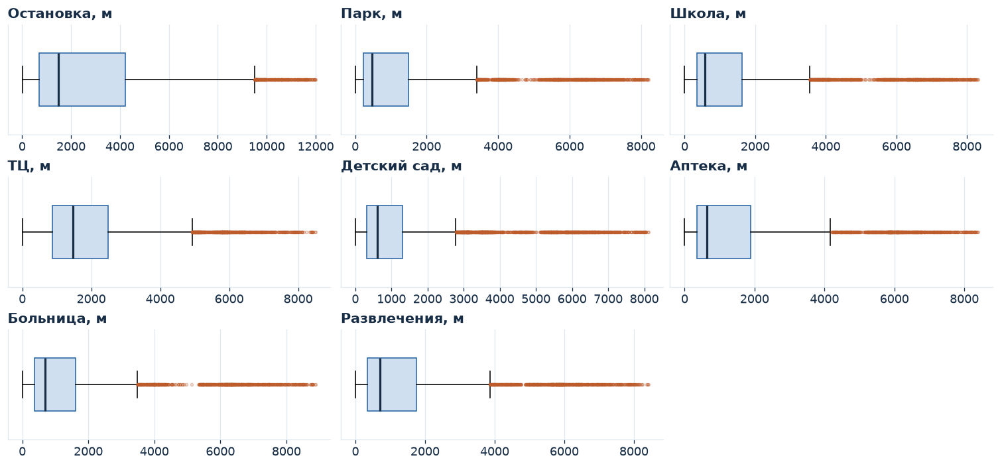

In [8]:
panels(distances[:8], box, short, ncols=3, height=2.0, data=data)

## 1.7 · Статистика остальных числовых полей

Дальние расстояния и высокие этажи могут быть корректными наблюдениями. Нулевые расстояния стоит проверять с учётом округления и геометрии объектов.

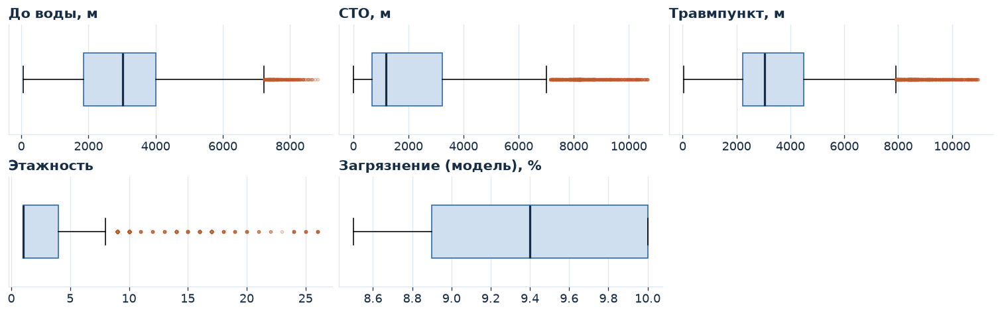

In [9]:
panels(numeric[8:], box, short, ncols=3, height=2.0, data=data)

In [10]:
stats = data[numeric].describe().T
stats = stats[['min', '25%', '50%', '75%', 'max', 'mean', 'std']]
stats = stats.rename(columns={
    'min': 'Мин.', '50%': 'Медиана', '75%': 'Q3',
    'max': 'Макс.', 'mean': 'Среднее', 'std': 'Ст. откл.',
})
print(stats.rename(index=short).round(1).to_string())

                         Мин.     25%  Медиана      Q3    Макс.  Среднее  Ст. откл.
Остановка, м              8.0   684.8   1475.0  4212.5  11997.0   2597.0     2798.5
Парк, м                   7.0   234.0    475.0  1502.0   8218.0   1323.9     1819.1
Школа, м                  0.0   340.0    573.0  1622.8   8310.0   1431.7     1879.1
ТЦ, м                     0.0   875.0   1474.0  2494.2   8508.0   2014.7     1646.0
Детский сад, м            3.0   309.0    610.0  1301.0   8124.0   1361.1     1772.4
Аптека, м                 1.0   357.0    643.5  1886.0   8392.0   1481.1     1824.6
Больница, м               0.0   361.8    697.0  1608.5   8886.0   1438.4     1802.4
Развлечения, м            0.0   340.8    700.0  1749.8   8426.0   1449.7     1741.0
До воды, м               52.0  1853.8   3015.0  4003.0   8813.0   3229.1     1768.0
СТО, м                    0.0   669.0   1182.0  3218.0  10682.0   2243.9     2380.1
Травмпункт, м            37.0  2233.0   3050.0  4503.5  10959.0   3653.1    

## 1.8 · Качество всех 24 полей

- **Нет данных** — пустые ячейки, пометка «информация отсутствует» и все значения в поле «Закрытый двор».
- **Одиночные** — значения, которые встретились один раз. **Различных** — сколько разных значений есть в столбце.
- **К проверке** — выбросы по правилу 1,5 IQR, нулевые расстояния, редкие категории (до 5 записей), неопределённые районы, адреса без цифр, неверные координаты, повторы и неположительные номера записей.
- Загрязнение рассчитано по модели, а класс жилья и часть материалов стен определены по косвенным признакам.

На графике показаны только столбцы с пропусками. Под ним — таблица по всем 24 полям. Сначала идут числовые, затем категориальные и служебные.

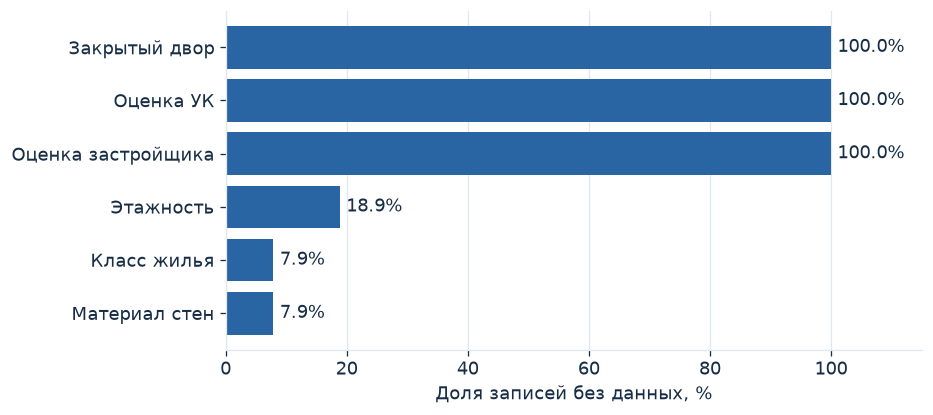

                         Нет данных  Одиночные  К проверке  Различных
Остановка, м                      0       2340         359       4413
Парк, м                           0       1701        1148       3093
Школа, м                          0       1781        1190       3124
ТЦ, м                             0       1785         821       3958
Детский сад, м                    0       1598        1523       3019
Аптека, м                         0       1753         916       3319
Больница, м                       0       1577        1023       3246
Развлечения, м                    0       1663         968       3361
До воды, м                        0       2268         281       4602
СТО, м                            0       2131         754       4115
Травмпункт, м                     0       2691         735       4972
Этажность                      1723          1        1022         26
Загрязнение (модель), %           0          0           0         16
Район               

In [11]:
review = {}
for col in numeric:
    values = data[col]
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    outlier = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
    review[col] = int((outlier | (values.eq(0) & (col in distances))).sum())

for col in categorical:
    values = data[col]
    counts = values.value_counts()
    review[col] = int(counts[counts <= 5].sum())
district_values = data[district]
district_counts = district_values.value_counts()
rare_districts = district_counts[district_counts <= 5].index
unknown_districts = district_values.str.contains('не определён', na=False)
review[district] = int((district_values.isin(rare_districts) | unknown_districts).sum())
review[address] = int((data[address].notna() & ~data[address].str.contains(r'\d', na=False)).sum())
review[coordinates] = int(data[coordinates].notna().sum() - len(geo))
review['№'] = int((data['№'].duplicated(keep=False) | data['№'].le(0)).sum())

quality = pd.DataFrame({
    'Нет данных': data.isna().sum(),
    'Одиночные': {col: int(data[col].value_counts().eq(1).sum()) for col in data},
    'К проверке': review,
    'Различных': data.nunique(),
}).loc[numeric + categorical + service]

missing = (quality['Нет данных'] / len(raw) * 100).sort_values()
missing = missing[missing.gt(0)].rename(index=short)
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
bars = ax.barh(missing.index, missing, color=blue)
ax.bar_label(bars, fmt='%.1f%%', padding=4)
ax.set(xlabel='Доля записей без данных, %', xlim=(0, 115))
ax.set_xticks(range(0, 101, 20))
ax.grid(axis='x', color=grid)
plt.show()

print(quality.rename(index=short).to_string())
repeating = data[address].value_counts().gt(1).sum()
print(f'\nПовторяются {repeating} адресов. Считаем записи о зданиях.')

## 1.9 · Расстояние до остановки по этажности

Для каждой группы показана медиана. Если она равна 800 м, примерно половина домов в этой группе находится в пределах 800 м от остановки по данным базы.

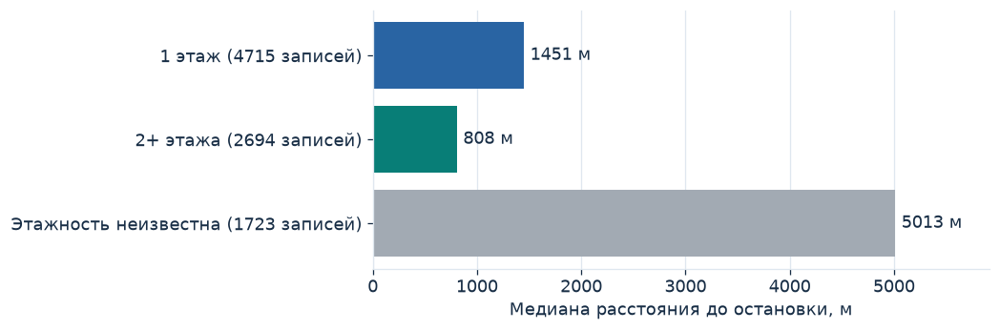

По всей базе: 1451 м у одноэтажных домов и 808 м у домов с 2+ этажами.
В отдельных районах разница может быть другой.


In [12]:
floor_groups = {
    '1 этаж': data[floors].eq(1),
    '2+ этажа': data[floors].ge(2),
    'Этажность неизвестна': data[floors].isna(),
}
floor_stats = pd.DataFrame({
    name: data.loc[mask, stop].agg(['median', 'count'])
    for name, mask in floor_groups.items()
}).T
group_labels = [
    f'{name} ({count:.0f} записей)'
    for name, count in floor_stats['count'].items()
]
fig, ax = plt.subplots(figsize=(9, 2.9), layout='constrained')
bars = ax.barh(group_labels, floor_stats['median'], color=[blue, teal, '#A2AAB3'])
ax.bar_label(bars, fmt='%.0f м', padding=4)
ax.invert_yaxis()
ax.margins(x=.18)
ax.set_xlabel('Медиана расстояния до остановки, м')
ax.grid(axis='x', color=grid)
plt.show()

m1, m2 = floor_stats['median'].iloc[:2]
print(f'По всей базе: {m1:.0f} м у одноэтажных домов и {m2:.0f} м у домов с 2+ этажами.')
print('В отдельных районах разница может быть другой.')

## 1.10 · Детские площадки и парковки

Сравниваем долю домов с площадкой в пределах 200 м в трёх группах по расстоянию до размеченной парковки.

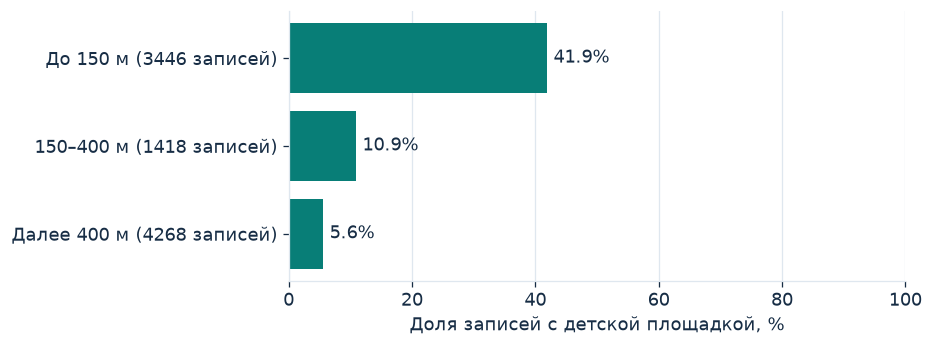

Площадка отмечена у 41.9% записей в группе до 150 м от парковки.
В группе дальше 400 м — у 5.6% записей.


In [13]:
parking_group = pd.Series({
    'наземная парковка рядом (до 150 м)': 'До 150 м',
    'парковка в радиусе 400 м': '150–400 м',
    'далее 400 м (нет парковки в данных)': 'Далее 400 м',
})
play = (data[playground].eq('да').groupby(data[parking]).agg(['mean', 'size'])
        .reindex(parking_group.index).set_axis(parking_group.values))
group_labels = [
    f'{name} ({count} записей)'
    for name, count in play['size'].items()
]
fig, ax = plt.subplots(figsize=(8, 2.9), layout='constrained')
bars = ax.barh(group_labels, play['mean'] * 100, color=teal)
ax.bar_label(bars, fmt='%.1f%%', padding=4)
ax.invert_yaxis()
ax.set(xlabel='Доля записей с детской площадкой, %', xlim=(0, 100))
ax.grid(axis='x', color=grid)
plt.show()

print(f'Площадка отмечена у {play["mean"].iloc[0]:.1%} записей в группе до 150 м от парковки.')
print(f'В группе дальше 400 м — у {play["mean"].iloc[-1]:.1%} записей.')

## 2.1 · Какие вопросы решает дашборд

**Покупатель жилья и консультант по недвижимости** сравнивают районы, а затем смотрят отдельные адреса.

| Вопрос | Что показывает дашборд |
|---|---|
| По каким районам достаточно записей для сравнения? | Число записей и размер выборки по району |
| Есть ли школа или детсад в радиусе 500 м? | Две доли. Для адреса доступны оба расстояния в подсказке |
| Где искать дом ближе к остановке? | Точки домов по координатам с цветом по расстоянию до остановки |
| Каковы типичные расстояния до остановки и парка? | Две медианы, в метрах, и таблица для сравнения районов |

Для районных сравнений выбран порог **30 записей**. Порог 500 м — ориентир для сравнения по прямой. Возраст дома, цена и маршруты в базе отсутствуют.

## 2.2 · Дашборд доступности инфраструктуры

Наведите курсор на точку, чтобы увидеть адрес и расстояния. Выделите область на схеме, чтобы приблизить её. Серии на графиках сравнения можно скрыть кликом по легенде.

In [14]:
district_counts = data[district].value_counts()
covered = district_counts[district_counts >= 30].index
sample = data.loc[data[district].isin(covered)]
grouped = sample.groupby(district)
summary = grouped.size().reindex(covered).to_frame('Записей')
nearby_columns = {school: 'Школа ≤500 м', kindergarten: 'Детсад ≤500 м'}
for col, name in nearby_columns.items():
    # Считаем долю только среди домов, для которых есть расстояние.
    known = sample.dropna(subset=[col])
    summary[name] = known[col].le(500).groupby(known[district]).mean()
summary['Остановка, медиана, м'] = grouped[stop].median()
summary['Парк, медиана, м'] = grouped[park].median()

points = sample.join(geo, how='inner')

dashboard = make_subplots(
    rows=3, cols=2, row_heights=[.36, .36, .28],
    specs=[[{}, {}], [{}, {}], [{'type': 'table', 'colspan': 2}, None]],
    horizontal_spacing=.15, vertical_spacing=.105,
    subplot_titles=['Записи по районам', 'Дома в радиусе 500 м от объекта',
                    'Дома по координатам', 'Типичные расстояния до остановки и парка',
                    'Сравнение районов'],
)
district_bar(dashboard, summary['Записей'], 'Записей', blue, 1, 1, showlegend=False)
district_bar(dashboard, summary['Школа ≤500 м'], 'Школа', blue, 1, 2, fmt='.1%')
district_bar(dashboard, summary['Детсад ≤500 м'], 'Детсад', teal, 1, 2, fmt='.1%')
district_bar(dashboard, summary['Остановка, медиана, м'], 'Остановка', amber, 2, 2)
district_bar(dashboard, summary['Парк, медиана, м'], 'Парк', '#7764A5', 2, 2)
for row, col in [(1, 1), (1, 2), (2, 2)]:
    dashboard.update_yaxes(autorange='reversed', row=row, col=col)
dashboard.update_xaxes(title='Записей', rangemode='tozero', row=1, col=1)
dashboard.update_xaxes(title='Доля записей', tickformat='.0%', range=[0, 1], row=1, col=2)
dashboard.update_xaxes(title='Медиана, м', rangemode='tozero', row=2, col=2)

dashboard.add_trace(go.Scatter(
    x=points['Долгота'], y=points['Широта'], mode='markers',
    text=points[address], customdata=points[[district, stop, school, kindergarten, park]],
    marker=dict(
        size=4, opacity=.75, color=points[stop], colorscale='Cividis',
        showscale=True,
        colorbar=dict(title=dict(text='Остановка, м', font=dict(size=11)),
                      x=.425, y=.44, len=.28, thickness=10),
    ),
    showlegend=False,
    hovertemplate=('<b>%{text}</b><br>%{customdata[0]} район'
                   '<br>Остановка: %{customdata[1]:,} м<br>Школа: %{customdata[2]:,} м'
                   '<br>Детсад: %{customdata[3]:,} м<br>Парк: %{customdata[4]:,} м<extra></extra>'),
), 2, 1)
dashboard.update_xaxes(title='Долгота, °', row=2, col=1)
dashboard.update_yaxes(title='Широта, °', row=2, col=1)

percent_formats = dict.fromkeys(nearby_columns.values(), '.1%')
table_values = []
for col in summary:
    fmt = percent_formats.get(col, ',.0f')
    table_values.append([format(value, fmt) for value in summary[col]])
dashboard.add_trace(go.Table(
    columnwidth=[1.25, .7, 1, 1, 1.5, 1.3],
    header=dict(values=['Район', *summary.columns], fill_color=ink,
                font=dict(color='white', size=13), align='left', height=29),
    cells=dict(values=[list(summary.index), *table_values],
               fill_color=[['#EFF5FB', '#FAFCFE'] * len(summary)], height=27,
               align='left', font=dict(color=ink, size=12)),
), 3, 1)

style(dashboard, 840).update_layout(
    title=dict(text='Доступность инфраструктуры в базе жилых домов Красноярска',
               x=.05, font=dict(size=23)),
    barmode='group', legend=dict(orientation='h', x=1, xanchor='right', y=1.10, yanchor='top'),
    margin=dict(l=120, r=40, t=120, b=55), hoverlabel=dict(namelength=-1),
)
dashboard.add_annotation(
    text='Данные OpenStreetMap из исходной книги. Расстояния по прямой. Покрытие города неполное.',
    x=0, y=-.045, xref='paper', yref='paper', xanchor='left', showarrow=False,
    font=dict(size=11, color='#4B6278'),
)
dashboard.show(config={'displaylogo': False})
print(
    f'На графиках и в таблице {len(sample):,} записей из {len(summary)} районов. '
    f'Ещё {len(raw) - len(sample)} записей относятся к малым или неопределённой группам. '
    'Расстояния по прямой до объектов в исходной выгрузке.'
)

На графиках и в таблице 9,123 записей из 4 районов. Ещё 9 записей относятся к малым или неопределённой группам. Расстояния по прямой до объектов в исходной выгрузке.


## Выводы по выборке

Медианы ниже показывают типичные расстояния по записям из четырёх районов. В районах с неполной разметкой расстояния до найденных объектов могут быть завышены.

In [15]:
district_table = summary.copy()
for col in nearby_columns.values():
    district_table[col] = summary[col].map('{:.1%}'.format)
print(district_table.to_string(float_format='{:.0f}'.format))

stops = summary['Остановка, медиана, м']
nearest, farthest = stops.idxmin(), stops.idxmax()
print()
print(f'По данным базы: {nearest} — {stops[nearest]:.0f} м до остановки по медиане,')
print(f'{farthest} — {stops[farthest]:.0f} м. Расстояния указаны по прямой.')

                 Записей Школа ≤500 м Детсад ≤500 м  Остановка, медиана, м  Парк, медиана, м
Район                                                                                       
Центральный         5908        57.0%         54.4%                   1169               355
Советский           2403         0.3%          1.6%                   5984              3336
Железнодорожный      565        61.1%         83.5%                    500               223
Кировский            247        82.2%         70.9%                    408               286

По данным базы: Кировский — 408 м до остановки по медиане,
Советский — 5984 м. Расстояния указаны по прямой.
